# 3. QQQ Daily RSI(2) Mean Reversion - Robustness Battery & Validation Gate
## Systematic Trading Approach following Alphaca Framework

This notebook executes the full multi-phase statistical robustness battery and validation gate for the **Alphaca RSI(2) Mean Reversion** strategy on **QQQ daily bars**.

### Robustness Battery Scope:
1. **Phase 1 · Out-Of-Sample Validation**: Performance evaluation on untouched OOS data (2018-09-17 to present) under both 100% Capital and 1% Risk ATR sizing.
2. **Phase 2 · Walk-Forward Analysis**: 23 rolling 3-year In-Sample / 1-year Out-of-Sample windows with strictly fixed rules.
3. **Phase 3 · Block Monte Carlo Simulation**: 10,000 circular block resamplings (block=5) to preserve winning/losing streaks and stress-test tail risk.
4. **Phase 4 · Monkey Test**: 2,000 synthetic portfolios using identical trade durations and filter eligibility to rule out market-drift artifacts.
5. **Phase 5 · Stress Testing**: Doubled execution costs (10 bps/side), removal of the 2 best years, and performance during major historical crisis regimes (2000-2002, 2008, 2022).
6. **Phase 6 · Edge Decay Analysis**: Rolling 40-trade Profit Factor and recent vs. historical performance tracking.
7. **Phase 7 · Full Validation Gate**: Automated execution of all gating criteria via `validation_gate.py`.

In [1]:
# Strategy parameters
SMA_LEN = 230
RSI_THR = 20.0


## 1. IMPORTS AND CONFIG

In [2]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

utils_path = os.path.abspath('../../utils')
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
sys.path.insert(0, os.path.abspath('.'))

from utils import compute_metrics, plot_equity_curve
from metrics import sharpe_ratio, max_drawdown
from robustness import monte_carlo_block, monkey_test, grid_search, plateau_check, plot_grid, plot_monkey
from edge_decay import rolling_pf, plot_rolling_pf, pf_by_year, edge_decay_summary
from validation_gate import run_validation
import rsi2_engine as eng

print("Imports complete.")
print(f"Loaded utils from: {utils_path}")

Imports complete.
Loaded utils from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/utils


## 2. OUT-OF-SAMPLE (OOS) PERFORMANCE & COMPARISON

IN-SAMPLE VS. OUT-OF-SAMPLE PERFORMANCE COMPARISON
OOS Period: 2018-09-24 to 2026-10-14


,Metric,IS (Capital),OOS (Capital),IS (ATR 1% Risk),OOS (ATR 1% Risk)
0,Trades Count (N),237,123,237,123
1,Win Rate (%),65.8%,78.0%,65.8%,78.0%
2,Profit Factor,1.875,2.513,1.905,2.330
3,Expectancy (% per trade),0.504%,0.777%,0.171%,0.240%
4,Sharpe Ratio (Daily MTM),0.56,1.01,0.63,0.95
5,Max Drawdown (Daily MTM),-21.79%,-12.14%,-6.69%,-4.68%


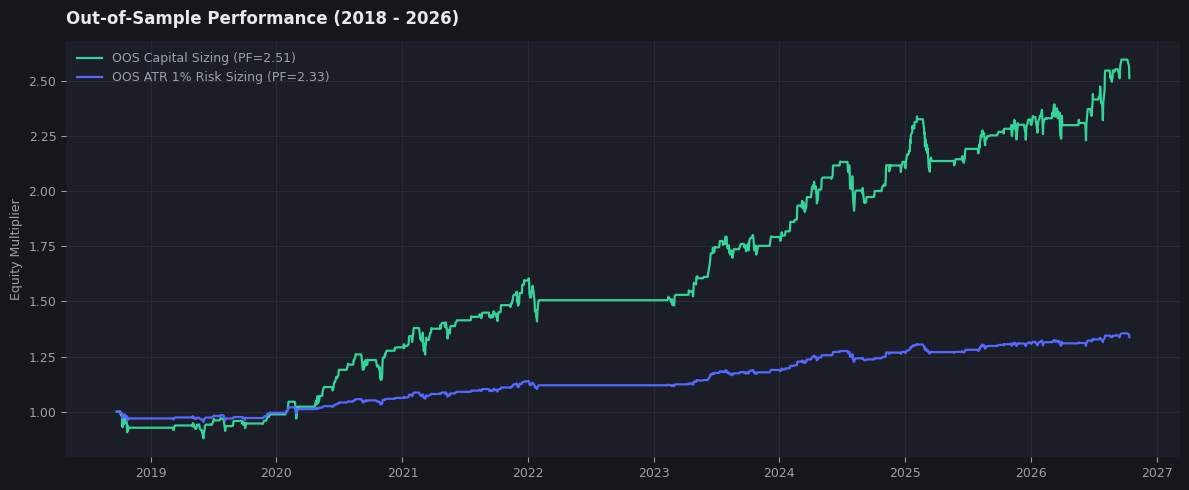

In [3]:
OOS_START = pd.Timestamp("2018-09-24")          # matching split date

df_raw = eng.load_qqq(start="1999-01-01")
common_start = eng.prepare(df_raw, sma_len=SMA_LEN).index[0]   # common start across grid
df = eng.prepare(df_raw, sma_len=SMA_LEN)
df = df[df.index >= common_start]

n_is = int((df.index < OOS_START).sum())
df_is, df_oos = df.iloc[:n_is].copy(), df.iloc[n_is:].copy()
oos_start = df_oos.index[0]

# Run baseline backtest on full dataset and separate slices
trades_all = eng.run_rsi2_backtest(df,     rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode="2green", slip_bps_per_side=5.0)
trades_is  = eng.run_rsi2_backtest(df_is,  rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode="2green", slip_bps_per_side=5.0)
trades_oos = eng.run_rsi2_backtest(df_oos, rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode="2green", slip_bps_per_side=5.0)

# Form ATR-sized trades DataFrame
trades_atr = trades_all.assign(pnl=trades_all['pnl_atr'], win=trades_all['pnl_atr'] > 0)
trades_is_atr = trades_is.assign(pnl=trades_is['pnl_atr'], win=trades_is['pnl_atr'] > 0)
trades_oos_atr = trades_oos.assign(pnl=trades_oos['pnl_atr'], win=trades_oos['pnl_atr'] > 0)

# Compute daily mark-to-market returns
ret_cap_is = eng.daily_returns(df_is, trades_is, sizing="capital")
ret_cap_oos = eng.daily_returns(df_oos, trades_oos, sizing="capital")
ret_atr_is = eng.daily_returns(df_is, trades_is, sizing="atr")
ret_atr_oos = eng.daily_returns(df_oos, trades_oos, sizing="atr")

eq_cap_oos = (1 + ret_cap_oos).cumprod()
eq_atr_oos = (1 + ret_atr_oos).cumprod()

oos_comparison = pd.DataFrame([
    {
        'Metric': 'Trades Count (N)',
        'IS (Capital)': len(trades_is),
        'OOS (Capital)': len(trades_oos),
        'IS (ATR 1% Risk)': len(trades_is_atr),
        'OOS (ATR 1% Risk)': len(trades_oos_atr)
    },
    {
        'Metric': 'Win Rate (%)',
        'IS (Capital)': f"{trades_is['win'].mean()*100:.1f}%",
        'OOS (Capital)': f"{trades_oos['win'].mean()*100:.1f}%",
        'IS (ATR 1% Risk)': f"{trades_is_atr['win'].mean()*100:.1f}%",
        'OOS (ATR 1% Risk)': f"{trades_oos_atr['win'].mean()*100:.1f}%"
    },
    {
        'Metric': 'Profit Factor',
        'IS (Capital)': f"{compute_metrics(trades_is, 1.0)['profit_factor']:.3f}",
        'OOS (Capital)': f"{compute_metrics(trades_oos, 1.0)['profit_factor']:.3f}",
        'IS (ATR 1% Risk)': f"{compute_metrics(trades_is_atr, 1.0)['profit_factor']:.3f}",
        'OOS (ATR 1% Risk)': f"{compute_metrics(trades_oos_atr, 1.0)['profit_factor']:.3f}"
    },
    {
        'Metric': 'Expectancy (% per trade)',
        'IS (Capital)': f"{trades_is['pnl'].mean():.3f}%",
        'OOS (Capital)': f"{trades_oos['pnl'].mean():.3f}%",
        'IS (ATR 1% Risk)': f"{trades_is_atr['pnl'].mean():.3f}%",
        'OOS (ATR 1% Risk)': f"{trades_oos_atr['pnl'].mean():.3f}%"
    },
    {
        'Metric': 'Sharpe Ratio (Daily MTM)',
        'IS (Capital)': f"{sharpe_ratio(ret_cap_is):.2f}",
        'OOS (Capital)': f"{sharpe_ratio(ret_cap_oos):.2f}",
        'IS (ATR 1% Risk)': f"{sharpe_ratio(ret_atr_is):.2f}",
        'OOS (ATR 1% Risk)': f"{sharpe_ratio(ret_atr_oos):.2f}"
    },
    {
        'Metric': 'Max Drawdown (Daily MTM)',
        'IS (Capital)': f"{max_drawdown((1+ret_cap_is).cumprod())*100:.2f}%",
        'OOS (Capital)': f"{max_drawdown(eq_cap_oos)*100:.2f}%",
        'IS (ATR 1% Risk)': f"{max_drawdown((1+ret_atr_is).cumprod())*100:.2f}%",
        'OOS (ATR 1% Risk)': f"{max_drawdown(eq_atr_oos)*100:.2f}%"
    }
])

print("=" * 80)
print("IN-SAMPLE VS. OUT-OF-SAMPLE PERFORMANCE COMPARISON")
print(f"OOS Period: {oos_start.strftime('%Y-%m-%d')} to {df_oos.index[-1].strftime('%Y-%m-%d')}")
print("=" * 80)
display(oos_comparison)

# Plot OOS Equity Curves
fig, ax = plt.subplots(figsize=(12, 5), facecolor='#15171c')
ax.set_facecolor('#1b1e26')
ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(colors='#9aa0ab', labelsize=9)

ax.plot(df_oos.index, eq_cap_oos, color='#34d399', lw=1.6, label=f'OOS Capital Sizing (PF={compute_metrics(trades_oos, 1.0)["profit_factor"]:.2f})')
ax.plot(df_oos.index, eq_atr_oos, color='#5468ff', lw=1.6, label=f'OOS ATR 1% Risk Sizing (PF={compute_metrics(trades_oos_atr, 1.0)["profit_factor"]:.2f})')
ax.set_title('Out-of-Sample Performance (2018 - 2026)', color='#e8e9ec', fontweight='bold', fontsize=12, loc='left', pad=12)
ax.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

## 3. WALK-FORWARD ANALYSIS (FIXED RULES: 3Y IS / 1Y OOS)

WALK-FORWARD ANALYSIS SUMMARY (23 ROLLING WINDOWS)
Walk-Forward Efficiency (OOS Mean / IS Annual Mean) : 1.092 (Threshold >= 0.50)
Positive OOS Years Ratio                           : 69.6% (16/23) (Threshold >= 60%)
Worst Single-Year OOS Drawdown                     : -13.76% (Threshold > -20%)
Walk-Forward Gate Verdict                          : PASSED


,year,ret_is_anual,ret_oos,n_oos,pf_oos,mdd_oos
0,2003,0.053904,0.346181,17,55.503434,-0.060834
1,2004,0.115394,-0.012037,12,0.910582,-0.091110
2,2005,0.109992,-0.023869,15,0.737870,-0.064510
3,2006,0.088611,0.125538,15,2.803900,-0.077895
4,2007,0.031152,0.201285,17,4.791920,-0.073731
5,2008,0.121195,-0.027189,3,0.259471,-0.058119
6,2009,0.080567,-0.004374,10,0.958879,-0.082296
7,2010,0.032793,0.039394,14,1.370149,-0.104508
8,2011,0.002237,0.006199,16,1.081054,-0.137553
9,2012,0.020030,0.069699,17,1.620209,-0.088387


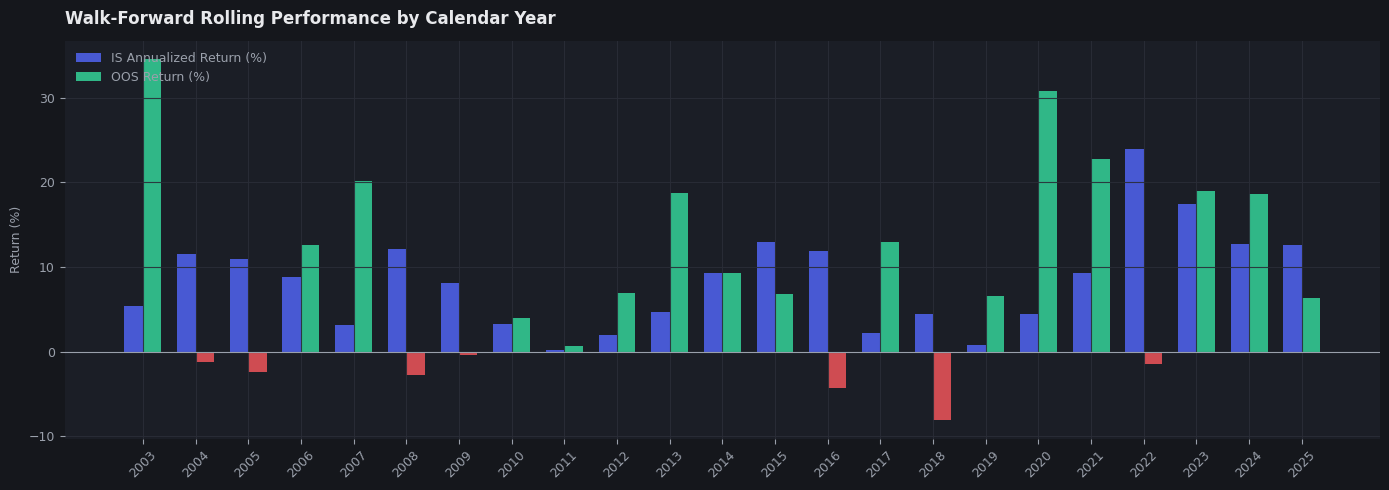

In [4]:
wf_df = eng.walk_forward_fixed(df, rules={"rsi_thr": RSI_THR, "sma_len": SMA_LEN}, is_years=3)

mean_is = wf_df['ret_is_anual'].mean()
mean_oos = wf_df['ret_oos'].mean()
efficiency = mean_oos / mean_is if mean_is > 0 else np.nan
pct_positive_years = (wf_df['ret_oos'] > 0).mean()
worst_oos_mdd = wf_df['mdd_oos'].min()

wf_pass = (efficiency >= 0.5) and (pct_positive_years >= 0.60) and (worst_oos_mdd > -0.20)

print("=" * 70)
print("WALK-FORWARD ANALYSIS SUMMARY (23 ROLLING WINDOWS)")
print("=" * 70)
print(f"Walk-Forward Efficiency (OOS Mean / IS Annual Mean) : {efficiency:.3f} (Threshold >= 0.50)")
print(f"Positive OOS Years Ratio                           : {pct_positive_years*100:.1f}% ({int(pct_positive_years*len(wf_df))}/{len(wf_df)}) (Threshold >= 60%)")
print(f"Worst Single-Year OOS Drawdown                     : {worst_oos_mdd*100:.2f}% (Threshold > -20%)")
print(f"Walk-Forward Gate Verdict                          : {'PASSED' if wf_pass else 'FAILED'}")
print("=" * 70)

display(wf_df)

# Plot Walk-Forward Annual Comparison
fig, ax = plt.subplots(figsize=(14, 5), facecolor='#15171c')
ax.set_facecolor('#1b1e26')
ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(colors='#9aa0ab', labelsize=9)

x = np.arange(len(wf_df))
width = 0.35
ax.bar(x - width/2, wf_df['ret_is_anual']*100, width, label='IS Annualized Return (%)', color='#5468ff', alpha=0.8)
colors_oos = ['#34d399' if r > 0 else '#f0555a' for r in wf_df['ret_oos']]
ax.bar(x + width/2, wf_df['ret_oos']*100, width, label='OOS Return (%)', color=colors_oos, alpha=0.85)

ax.axhline(0, color='#9aa0ab', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(wf_df['year'], rotation=45, color='#9aa0ab')
ax.set_title('Walk-Forward Rolling Performance by Calendar Year', color='#e8e9ec', fontweight='bold', fontsize=12, loc='left', pad=12)
ax.set_ylabel('Return (%)', color='#9aa0ab', fontsize=9)
ax.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

## 4. BLOCK MONTE CARLO BOOTSTRAP (10,000 SIMULATIONS)

BLOCK MONTE CARLO SUMMARY (10,000 RUNS)


,Metric,Capital Sizing,ATR Sizing
0,Median Compound Return (p50),685.9%,100.0%
1,5th Percentile Return (p5),292.8%,59.3%
2,Median Max Drawdown (mdd_p50),-21.79%,-6.83%
3,Worst 5% Drawdown (mdd_p5),-29.96%,-10.29%
4,Worst Simulation Drawdown,-44.17%,-17.76%
5,Probability of Ruin (50% DD),0.00%,0.00%
6,Probability of Positive Return,100.00%,100.00%


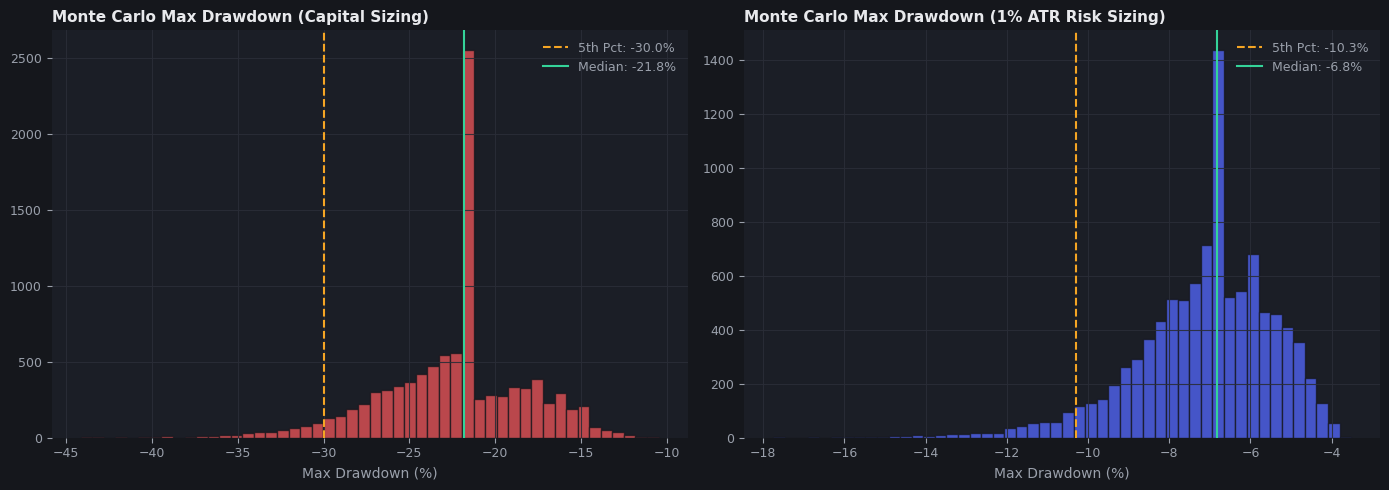

In [5]:
# Execute 10,000 circular block resamplings (block size = 5 trades)
# Drawdowns are measured on daily MTM: each simulated path concatenates the daily paths of the sampled trades.
paths_cap = eng.trade_mtm_paths(df, trades_all, sizing="capital")
paths_atr = eng.trade_mtm_paths(df, trades_all, sizing="atr")

mc_cap = monte_carlo_block(trades_all, n_sim=10000, block=5, mode="compound", seed=42, mtm_paths=paths_cap)
mc_atr = monte_carlo_block(trades_atr, n_sim=10000, block=5, mode="compound", seed=42, mtm_paths=paths_atr)

mc_summary = pd.DataFrame([
    {
        'Metric': 'Median Compound Return (p50)',
        'Capital Sizing': f"{mc_cap['ret_p50']*100:.1f}%",
        'ATR Sizing': f"{mc_atr['ret_p50']*100:.1f}%"
    },
    {
        'Metric': '5th Percentile Return (p5)',
        'Capital Sizing': f"{mc_cap['ret_p5']*100:.1f}%",
        'ATR Sizing': f"{mc_atr['ret_p5']*100:.1f}%"
    },
    {
        'Metric': 'Median Max Drawdown (mdd_p50)',
        'Capital Sizing': f"{mc_cap['mdd_p50']*100:.2f}%",
        'ATR Sizing': f"{mc_atr['mdd_p50']*100:.2f}%"
    },
    {
        'Metric': 'Worst 5% Drawdown (mdd_p5)',
        'Capital Sizing': f"{mc_cap['mdd_p5']*100:.2f}%",
        'ATR Sizing': f"{mc_atr['mdd_p5']*100:.2f}%"
    },
    {
        'Metric': 'Worst Simulation Drawdown',
        'Capital Sizing': f"{mc_cap['mdd_worst']*100:.2f}%",
        'ATR Sizing': f"{mc_atr['mdd_worst']*100:.2f}%"
    },
    {
        'Metric': 'Probability of Ruin (50% DD)',
        'Capital Sizing': f"{mc_cap['prob_ruin']*100:.2f}%",
        'ATR Sizing': f"{mc_atr['prob_ruin']*100:.2f}%"
    },
    {
        'Metric': 'Probability of Positive Return',
        'Capital Sizing': f"{mc_cap['prob_positive']*100:.2f}%",
        'ATR Sizing': f"{mc_atr['prob_positive']*100:.2f}%"
    }
])

print("=" * 70)
print("BLOCK MONTE CARLO SUMMARY (10,000 RUNS)")
print("=" * 70)
display(mc_summary)

# Plot Monte Carlo Drawdown Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), facecolor='#15171c')
for ax in (ax1, ax2):
    ax.set_facecolor('#1b1e26')
    ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(colors='#9aa0ab', labelsize=9)

ax1.hist(mc_cap['mdds'] * 100, bins=50, color='#f0555a', alpha=0.75, edgecolor='#15171c')
ax1.axvline(mc_cap['mdd_p5'] * 100, color='#f5a524', ls='--', lw=1.5, label=f"5th Pct: {mc_cap['mdd_p5']*100:.1f}%")
ax1.axvline(mc_cap['mdd_p50'] * 100, color='#34d399', ls='-', lw=1.5, label=f"Median: {mc_cap['mdd_p50']*100:.1f}%")
ax1.set_title('Monte Carlo Max Drawdown (Capital Sizing)', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left')
ax1.set_xlabel('Max Drawdown (%)', color='#9aa0ab')
ax1.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9)

ax2.hist(mc_atr['mdds'] * 100, bins=50, color='#5468ff', alpha=0.75, edgecolor='#15171c')
ax2.axvline(mc_atr['mdd_p5'] * 100, color='#f5a524', ls='--', lw=1.5, label=f"5th Pct: {mc_atr['mdd_p5']*100:.1f}%")
ax2.axvline(mc_atr['mdd_p50'] * 100, color='#34d399', ls='-', lw=1.5, label=f"Median: {mc_atr['mdd_p50']*100:.1f}%")
ax2.set_title('Monte Carlo Max Drawdown (1% ATR Risk Sizing)', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left')
ax2.set_xlabel('Max Drawdown (%)', color='#9aa0ab')
ax2.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9)

plt.tight_layout()
plt.show()

## 5. MONKEY TEST (2,000 SYNTHETIC RANDOM PORTFOLIOS)

MONKEY TEST RESULTS
Strategy Realized Profit Factor : 2.079
Random Monkey Median PF         : 1.220
Share of Monkeys Outperformed   : 100.00% (Threshold >= 95.0%)
Monkey Test Verdict             : PASSED


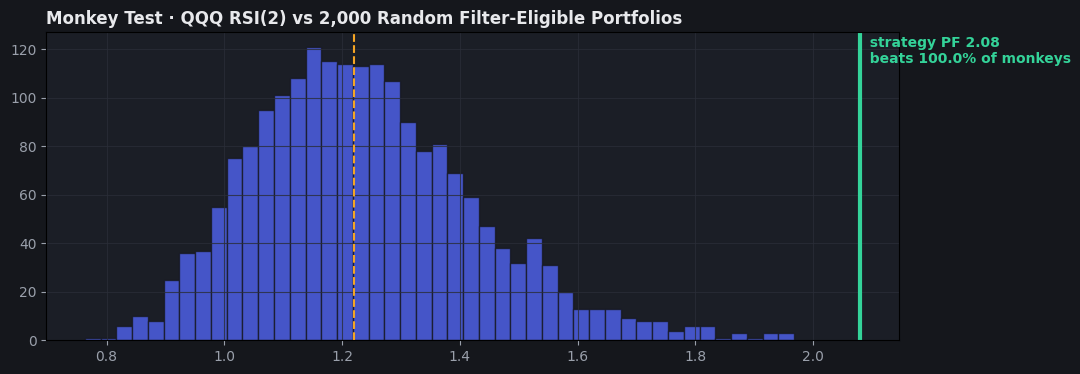

In [6]:
# Eligible filter condition: Close > SMA evaluated at t-1 (shifted by 1 for execution at open)
eligible = (df['close'] > df['sma']).shift(1)

mk = monkey_test(
    df=df,
    trades_df=trades_all,
    eligible=eligible,
    n_sim=2000,
    entry_col="open",
    exit_col="open",
    cost_pct_per_side=0.05,
    seed=42
)

print("=" * 70)
print("MONKEY TEST RESULTS")
print("=" * 70)
print(f"Strategy Realized Profit Factor : {mk['pf_real']:.3f}")
print(f"Random Monkey Median PF         : {mk['pf_monkey_median']:.3f}")
print(f"Share of Monkeys Outperformed   : {mk['pct_pf']*100:.2f}% (Threshold >= 95.0%)")
print(f"Monkey Test Verdict             : {'PASSED' if mk['pct_pf'] >= 0.95 else 'FAILED'}")
print("=" * 70)

plot_monkey(mk, title="Monkey Test · QQQ RSI(2) vs 2,000 Random Filter-Eligible Portfolios")

## 6. STRESS TESTING: COSTS X2, WINDFALL EXCLUSION & CRISIS REGIMES

In [7]:
print("=" * 70)
print("STRESS TESTING BATTERY")
print("=" * 70)

# 1. Costs x2 Stress (10 bps per side = 20 bps round trip)
trades_x2 = eng.run_rsi2_backtest(df, rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode="2green", slip_bps_per_side=10.0)
m_x2 = compute_metrics(trades_x2, 1.0, 0.0)

# 2. Exclude 2 Best Windfall Years
trades_all['year'] = pd.to_datetime(trades_all['entry_time']).dt.year
annual_pnl = trades_all.groupby('year')['pnl'].sum()
top_2_years = annual_pnl.sort_values(ascending=False).head(2).index.tolist()
trades_ex_top = trades_all[~trades_all['year'].isin(top_2_years)]
m_ex_top = compute_metrics(trades_ex_top, 1.0, 0.0)

# 3. Crisis Regimes
regimes = {
    'Dot-Com Bust (2000-2002)': (2000, 2002),
    'Great Financial Crisis (2008)': (2008, 2008),
    'Rate Hike Bear Market (2022)': (2022, 2022)
}

stress_rows = [
    {
        'Stress Scenario': 'Baseline (5 bps / side)',
        'Trades': len(trades_all),
        'Win Rate': f"{trades_all['win'].mean()*100:.1f}%",
        'Profit Factor': f"{compute_metrics(trades_all, 1.0)['profit_factor']:.3f}",
        'Expectancy': f"{trades_all['pnl'].mean():.2f}%",
        'Notes': 'Standard trading friction'
    },
    {
        'Stress Scenario': 'Costs x2 (10 bps / side)',
        'Trades': len(trades_x2),
        'Win Rate': f"{trades_x2['win'].mean()*100:.1f}%",
        'Profit Factor': f"{m_x2['profit_factor']:.3f}",
        'Expectancy': f"{m_x2['expectancy']:.2f}%",
        'Notes': 'Severe liquidity friction test'
    },
    {
        'Stress Scenario': f"Exclude Best Years ({top_2_years[0]}, {top_2_years[1]})",
        'Trades': len(trades_ex_top),
        'Win Rate': f"{trades_ex_top['win'].mean()*100:.1f}%",
        'Profit Factor': f"{m_ex_top['profit_factor']:.3f}",
        'Expectancy': f"{m_ex_top['expectancy']:.2f}%",
        'Notes': 'Test resilience without top windfalls'
    }
]

for name, (start_y, end_y) in regimes.items():
    t_reg = trades_all[(trades_all['year'] >= start_y) & (trades_all['year'] <= end_y)]
    if len(t_reg) > 0:
        m_r = compute_metrics(t_reg, 1.0, 0.0)
        stress_rows.append({
            'Stress Scenario': name,
            'Trades': len(t_reg),
            'Win Rate': f"{t_reg['win'].mean()*100:.1f}%",
            'Profit Factor': f"{m_r['profit_factor']:.3f}",
            'Expectancy': f"{m_r['expectancy']:.2f}%",
            'Notes': 'Macro trend filter active'
        })
    else:
        stress_rows.append({
            'Stress Scenario': name,
            'Trades': 0,
            'Win Rate': 'N/A',
            'Profit Factor': 'N/A',
            'Expectancy': 'N/A',
            'Notes': '100% capital protected in cash'
        })

stress_df = pd.DataFrame(stress_rows)
display(stress_df)

STRESS TESTING BATTERY


,Stress Scenario,Trades,Win Rate,Profit Factor,Expectancy,Notes
0,Baseline (5 bps / side),360,70.3%,2.079,0.60%,Standard trading friction
1,Costs x2 (10 bps / side),360,68.9%,1.852,0.50%,Severe liquidity friction test
2,"Exclude Best Years (2003, 2020)",329,68.7%,1.811,0.48%,Test resilience without top windfalls
3,Dot-Com Bust (2000-2002),10,60.0%,2.049,1.65%,Macro trend filter active
4,Great Financial Crisis (2008),3,33.3%,0.104,-2.74%,Macro trend filter active
5,Rate Hike Bear Market (2022),2,0.0%,0.000,-2.84%,Macro trend filter active


## 7. EDGE DECAY & TEMPORAL STABILITY

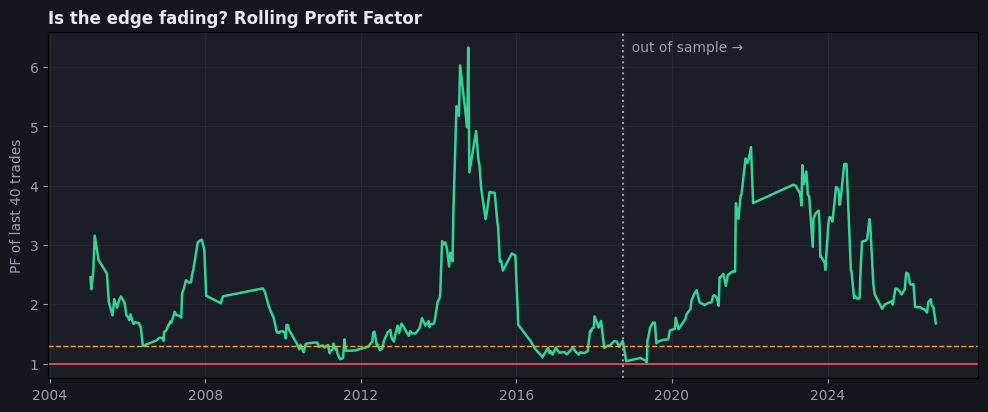

ANNUAL PERFORMANCE BREAKDOWN


,n,pf,expectancy,win_rate,total_pnl
year,,,,,
2000,10,2.049,1.650,0.600,16.502
2003,17,55.503,1.772,0.882,30.126
2004,12,0.911,-0.082,0.500,-0.978
2005,14,0.674,-0.223,0.429,-3.122
2006,16,3.038,0.859,0.812,13.738
2007,17,4.792,1.097,0.765,18.657
2008,3,0.104,-2.744,0.333,-8.232
2009,10,0.959,-0.030,0.500,-0.299
2010,14,1.370,0.299,0.571,4.182


EDGE DECAY DIAGNOSTIC SUMMARY:
Historical PF (prior to last 3 years) : 1.970
Recent PF (last 3 full years)         : 2.777
Recent / Historical Expectancy Ratio  : 1.429
Edge Decay Warning Flag               : False


In [8]:
roll = rolling_pf(trades_all, window=40, cap=8.0, date_col="exit_time")
plot_rolling_pf(roll, oos_start=oos_start, window=40)

by_year = pf_by_year(trades_all, date_col="exit_time")
print("=" * 70)
print("ANNUAL PERFORMANCE BREAKDOWN")
print("=" * 70)
display(by_year.round(3))

decay_summary = edge_decay_summary(trades_all, last_n=3, date_col="exit_time")
print("=" * 70)
print("EDGE DECAY DIAGNOSTIC SUMMARY:")
print("=" * 70)
print(f"Historical PF (prior to last 3 years) : {decay_summary['historical']['pf']:.3f}")
print(f"Recent PF (last 3 full years)         : {decay_summary['recent']['pf']:.3f}")
print(f"Recent / Historical Expectancy Ratio  : {decay_summary['expectancy_ratio']:.3f}")
print(f"Edge Decay Warning Flag               : {decay_summary['warning']}")
print("=" * 70)

## 8. FULL VALIDATION GATE RUN (AUTOMATED MULTI-PHASE AUDIT)

In [9]:
# Recompute in-sample parameter grid independently (no imported state)
rsi_vals = [5, 10, 15, 20, 25, 30]
sma_vals = [SMA_LEN + 30 * k for k in range(-3, 3)]   # always contains SMA_LEN (230 -> 140..290)
is_dfs = {s: eng.prepare(df_raw, sma_len=s)[eng.prepare(df_raw, sma_len=s).index < oos_start] for s in sma_vals}

def evaluate_gate(rsi, sma):
    d = is_dfs[sma]
    t = eng.run_rsi2_backtest(d, rsi_thr=rsi, sma_len=sma, exit_mode="2green", slip_bps_per_side=5.0)
    if len(t) == 0: return (0.0, 0)
    p = t['pnl'].values; g, l = p[p > 0].sum(), -p[p < 0].sum()
    return (float(g / l) if l > 0 else np.inf, int(len(t)))

pf_grid, n_grid = grid_search(evaluate_gate, rsi_vals, sma_vals)

# Run full validation gate on ATR-sized run (official determining run per Alphaca framework)
print("\n" + "=" * 70)
print("1. VALIDATION GATE: ATR-SIZED RUN (OFFICIAL VERDICT)")
print("=" * 70)
validation = run_validation(
    trades_df=trades_atr,
    df_prices=df,
    eligible=eligible,
    grid_pf=pf_grid,
    grid_n=n_grid,
    chosen=(int(RSI_THR), int(SMA_LEN)),
    oos_start=oos_start,
    mode="compound",
    mtm_paths=paths_atr,
    monkey_entry_col="open",
    monkey_exit_col="open",
    monkey_cost_pct_per_side=0.05,
    verbose=True
)

# Run validation gate on Capital-sized run for transparency
print("\n" + "=" * 70)
print("2. VALIDATION GATE: 100% CAPITAL SIZING RUN")
print("=" * 70)
validation_cap = run_validation(
    trades_df=trades_all,
    df_prices=df,
    eligible=eligible,
    grid_pf=pf_grid,
    grid_n=n_grid,
    chosen=(int(RSI_THR), int(SMA_LEN)),
    oos_start=oos_start,
    mode="compound",
    mtm_paths=paths_cap,
    monkey_entry_col="open",
    monkey_exit_col="open",
    monkey_cost_pct_per_side=0.05,
    verbose=True
)


1. VALIDATION GATE: ATR-SIZED RUN (OFFICIAL VERDICT)
VALIDATION GATE
[PASS] 1_oos: {'n': 123, 'pf': np.float64(2.33), 'pf_without_best_trade': np.float64(2.225), 'max_dd': -0.047, 'dd_basis': 'mtm'}
[PASS] 2_monte_carlo: {'ret_p5': 0.593, 'mdd_p5': -0.103, 'prob_ruin': 0.0, 'dd_basis': 'mtm'}
[PASS] 3_monkey: {'pf_real': 2.049, 'pct_pf': 1.0}
[PASS] 4_plateau: {'center_pf': 1.875, 'plateau': True, 'worst_drop_pct': 19.615}
[INFO] 5_edge_decay: {'recent_pf': 2.909, 'historical_pf': 1.932, 'warning': False}
------------------------------------------------------------ 
OVERALL: PASSED

2. VALIDATION GATE: 100% CAPITAL SIZING RUN
VALIDATION GATE
[PASS] 1_oos: {'n': 123, 'pf': np.float64(2.513), 'pf_without_best_trade': np.float64(2.408), 'max_dd': -0.121, 'dd_basis': 'mtm'}
[FAIL] 2_monte_carlo: {'ret_p5': 2.928, 'mdd_p5': -0.3, 'prob_ruin': 0.0, 'dd_basis': 'mtm'}
[PASS] 3_monkey: {'pf_real': 2.079, 'pct_pf': 1.0}
[PASS] 4_plateau: {'center_pf': 1.875, 'plateau': True, 'worst_drop_pct': 

## 9. STRATEGY METRICS DEFINITION & VERDICT

In [10]:
# Required metrics dict for utils/validate_strategy.py and CI gatekeeper
# ATR-sized, whole dataset period (1999-2026)
ret_series_atr = eng.daily_returns(df, trades_all, sizing="atr")
eq_series_atr = (1.0 + ret_series_atr).cumprod()

metrics = {
    "sharpe": float(sharpe_ratio(ret_series_atr)),
    "max_drawdown": float(max_drawdown(eq_series_atr)),
    "num_trades": int(len(trades_all))
}

print("=" * 70)
print("FINAL STRATEGY METRICS (ATR SIZING, WHOLE PERIOD):")
print("=" * 70)
print(f"Sharpe Ratio  : {metrics['sharpe']:.2f}")
print(f"Max Drawdown  : {metrics['max_drawdown']*100:.2f}%")
print(f"Total Trades  : {metrics['num_trades']}")
print(f"Validation Gate Overall: {validation['status']}")
print("=" * 70)

FINAL STRATEGY METRICS (ATR SIZING, WHOLE PERIOD):
Sharpe Ratio  : 0.73
Max Drawdown  : -6.69%
Total Trades  : 360
Validation Gate Overall: PASSED


## 10. VERDICT SUMMARY

In [11]:
from IPython.display import Markdown, display
from validation_gate import DEFAULTS as GATE

V, C = validation["phases"], validation_cap["phases"]

def tag(p):
    if p.get("skipped"):
        return "SKIP"
    if p.get("informational"):
        return "INFO"
    return "PASS" if p["passed"] else "FAIL"

def res(name):
    a, c = tag(V[name]), tag(C[name])
    return f"**{a}**" if a == c else f"**{a}** (ATR) / **{c}** (Capital)"

p1a, p1c = V["1_oos"], C["1_oos"]
p2a, p2c = V["2_monte_carlo"], C["2_monte_carlo"]
p3a, p3c = V["3_monkey"], C["3_monkey"]
p4a = V["4_plateau"]
p5a = V["5_edge_decay"]

d1 = (f"OOS PF = {p1a['pf']:.3f} (ATR) / {p1c['pf']:.3f} (Capital), "
      f"{p1a['n']} trades (min. {GATE['n_min']}), "
      f"MDD {p1a['max_dd']*100:.2f}% / {p1c['max_dd']*100:.2f}% "
      f"(limit {GATE['mdd_min']*100:.0f}%, basis {p1a['dd_basis']})")

d2 = (f"p5 return {p2a['ret_p5']*100:.1f}% / {p2c['ret_p5']*100:.1f}% (must be > 0), "
      f"p5 MDD {p2a['mdd_p5']*100:.2f}% / {p2c['mdd_p5']*100:.2f}% (limit {GATE['mc_mdd_p5_min']*100:.0f}%), "
      f"prob. of ruin {p2a['prob_ruin']*100:.2f}% / {p2c['prob_ruin']*100:.2f}% "
      f"(max {GATE['mc_ruin_max']*100:.0f}%)")

if p3a.get("skipped") or p3c.get("skipped"):
    d3 = "Phase skipped (no price data provided)"
else:
    d3 = (f"Strategy beats {p3a['pct_pf']*100:.1f}% (ATR) / {p3c['pct_pf']*100:.1f}% (Capital) "
          f"of random filter-eligible entries (min. {GATE['monkey_pct_min']*100:.0f}%)")

if p4a.get("skipped"):
    d4 = "Phase skipped (no parameter grid provided)"
else:
    d4 = (f"3x3 plateau: {'yes' if p4a['plateau'] else 'no'}; center PF = {p4a['center_pf']:.3f}; "
          f"worst neighbor drop = {p4a['worst_drop_pct']:.1f}% (max {GATE['plateau_max_drop']}%)")

trend = "higher" if p5a["recent_pf"] > p5a["historical_pf"] else "lower"
d5 = (f"Recent PF ({p5a['recent_pf']:.3f}) is {trend} than historical PF ({p5a['historical_pf']:.3f}); "
      f"{'edge decay WARNING' if p5a['warning'] else 'no decay warning'}")

status, status_cap = validation["status"], validation_cap["status"]

if status == "PASSED":
    summary = ("The Alphaca RSI(2) Mean Reversion strategy on QQQ daily bars passes every gating phase "
               "of the validation gate under ATR sizing (the official run).")
elif status == "INCOMPLETE":
    summary = ("No phase failed, but some phases were skipped: "
               f"{', '.join(validation['skipped'])}. An incomplete verdict does not count as a pass.")
else:
    failed = [n for n, p in V.items() if "passed" in p and not p["passed"]]
    summary = f"The validation gate FAILED under ATR sizing in: {', '.join(failed)}."

if status_cap != status:
    summary += f" Under 100% capital sizing the result is {status_cap}."

display(Markdown(f"""## 10. VERDICT SUMMARY

| Phase | Test Description | Result | Details |
| :--- | :--- | :---: | :--- |
| **Phase 1** | **Out-of-Sample Performance** | {res('1_oos')} | {d1} |
| **Phase 2** | **Block Monte Carlo (10k runs)** | {res('2_monte_carlo')} | {d2} |
| **Phase 3** | **Monkey Test (2,000 runs)** | {res('3_monkey')} | {d3} |
| **Phase 4** | **Parameter Plateau** | {res('4_plateau')} | {d4} |
| **Phase 5** | **Edge Decay Audit** | **INFO** | {d5} |

### OVERALL VERDICT (ATR, official): **{status}**  ·  Capital: **{status_cap}**

{summary}
"""))

## 10. VERDICT SUMMARY

| Phase | Test Description | Result | Details |
| :--- | :--- | :---: | :--- |
| **Phase 1** | **Out-of-Sample Performance** | **PASS** | OOS PF = 2.330 (ATR) / 2.513 (Capital), 123 trades (min. 30), MDD -4.68% / -12.14% (limit -20%, basis mtm) |
| **Phase 2** | **Block Monte Carlo (10k runs)** | **PASS** (ATR) / **FAIL** (Capital) | p5 return 59.3% / 292.8% (must be > 0), p5 MDD -10.29% / -29.96% (limit -25%), prob. of ruin 0.00% / 0.00% (max 5%) |
| **Phase 3** | **Monkey Test (2,000 runs)** | **PASS** | Strategy beats 100.0% (ATR) / 100.0% (Capital) of random filter-eligible entries (min. 95%) |
| **Phase 4** | **Parameter Plateau** | **PASS** | 3x3 plateau: yes; center PF = 1.875; worst neighbor drop = 19.6% (max 30%) |
| **Phase 5** | **Edge Decay Audit** | **INFO** | Recent PF (2.909) is higher than historical PF (1.932); no decay warning |

### OVERALL VERDICT (ATR, official): **PASSED**  ·  Capital: **FAILED**

The Alphaca RSI(2) Mean Reversion strategy on QQQ daily bars passes every gating phase of the validation gate under ATR sizing (the official run). Under 100% capital sizing the result is FAILED.
